In [1]:
from scipy import stats

# Example: Binomial distribution (n=10 trials, p=0.5 probability)
binom_dist = stats.binom(n=10, p=0.5)

pmf_val = binom_dist.pmf(5)        # P(X = 5)
cdf_val = binom_dist.cdf(5)        # P(X <= 5)
ppf_val = binom_dist.ppf(0.95)     # Quantile
samples = binom_dist.rvs(size=100) # Random samples

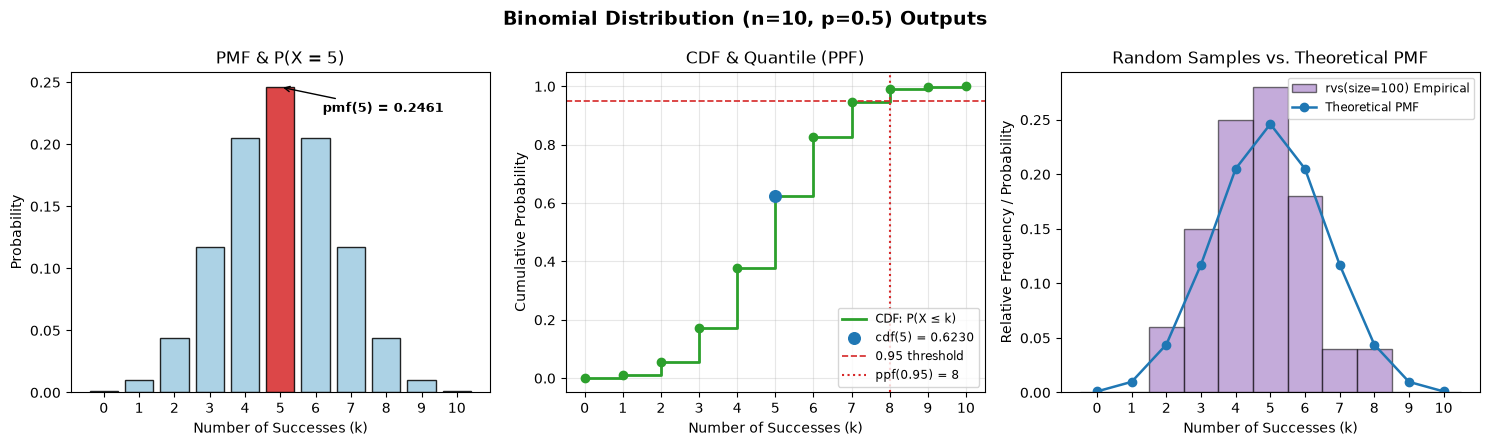

In [2]:
from scipy import stats

# Example: Binomial distribution (n=10 trials, p=0.5 probability)
binom_dist = stats.binom(n=10, p=0.5)

pmf_val = binom_dist.pmf(5)        # P(X = 5)
cdf_val = binom_dist.cdf(5)        # P(X <= 5)
ppf_val = binom_dist.ppf(0.95)     # Quantile
samples = binom_dist.rvs(size=100) # Random samples

# --- Visualization of the outputs above ---
import numpy as np
import matplotlib.pyplot as plt

k = np.arange(0, 11)
pmf_all = binom_dist.pmf(k)
cdf_all = binom_dist.cdf(k)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
fig.suptitle("Binomial Distribution (n=10, p=0.5) Outputs", fontsize=14, fontweight='bold')

# Panel 1: PMF & highlighted P(X = 5)
colors = ['#9ecae1' if val != 5 else '#d62728' for val in k]
axes[0].bar(k, pmf_all, color=colors, edgecolor='black', alpha=0.85)
axes[0].annotate(f'pmf(5) = {pmf_val:.4f}', xy=(5, pmf_val), xytext=(6.2, pmf_val - 0.02),
                 arrowprops=dict(arrowstyle='->', color='black'), fontsize=9.5, fontweight='bold')
axes[0].set_title('PMF & P(X = 5)')
axes[0].set_xlabel('Number of Successes (k)')
axes[0].set_ylabel('Probability')
axes[0].set_xticks(k)

# Panel 2: CDF, P(X <= 5) & PPF(0.95)
axes[1].step(k, cdf_all, where='post', color='#2ca02c', lw=2, label='CDF: P(X ≤ k)')
axes[1].scatter(k, cdf_all, color='#2ca02c', zorder=4)
axes[1].scatter([5], [cdf_val], color='#1f77b4', s=70, zorder=5, label=f'cdf(5) = {cdf_val:.4f}')
axes[1].axhline(0.95, color='#d62728', linestyle='--', lw=1.2, label='0.95 threshold')
axes[1].axvline(ppf_val, color='#d62728', linestyle=':', lw=1.5, label=f'ppf(0.95) = {int(ppf_val)}')
axes[1].set_title('CDF & Quantile (PPF)')
axes[1].set_xlabel('Number of Successes (k)')
axes[1].set_ylabel('Cumulative Probability')
axes[1].set_xticks(k)
axes[1].legend(loc='lower right', fontsize=8.5)
axes[1].grid(True, alpha=0.3)

# Panel 3: Random Samples (rvs) vs Theoretical PMF
bins = np.arange(-0.5, 11.5, 1)
axes[2].hist(samples, bins=bins, density=True, color='#9467bd', alpha=0.55, edgecolor='black', label='rvs(size=100) Empirical')
axes[2].plot(k, pmf_all, 'o-', color='#1f77b4', lw=1.8, label='Theoretical PMF')
axes[2].set_title('Random Samples vs. Theoretical PMF')
axes[2].set_xlabel('Number of Successes (k)')
axes[2].set_ylabel('Relative Frequency / Probability')
axes[2].set_xticks(k)
axes[2].legend(loc='upper right', fontsize=8.5)

plt.tight_layout()
plt.show()